<a href="https://colab.research.google.com/github/Ximearex/AI/blob/main/P5_Traslaciones_PDI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Práctica 5. Tipos de Traslaciones de Imágenes**
**Procesamiento Digital de Imágenes y Laboratorio – FIME UANL**

**Competencia:** aplicar y distinguir distintos tipos de transformaciones geométricas en imágenes mediante Python, OpenCV y NumPy.

**Objetivo:** implementar y comparar diferentes tipos de traslaciones y transformaciones geométricas en imágenes digitales, evaluando su impacto visual y sus aplicaciones prácticas en el análisis de imágenes.

## Imágenes médicas utilizadas

Se usan dos imágenes médicas, ambas tomadas del repositorio público *COVID-19 Image Data Collection* (Cohen et al., 2020). Originalmente fueron publicadas como casos clínicos en Eurorad con licencia CC BY-NC-SA 4.0.

La siguiente celda descarga las dos imágenes directamente al entorno de Colab.

In [1]:
!wget -q -O TC_torax.jpg https://raw.githubusercontent.com/ieee8023/covid-chestxray-dataset/master/images/16689_1_1.jpg
!wget -q -O RX_torax.jpg https://raw.githubusercontent.com/ieee8023/covid-chestxray-dataset/master/images/16663_1_1.jpg
!ls -lh *.jpg

-rw-r--r-- 1 root root 361K Nov  9 07:37 RX_torax.jpg
-rw-r--r-- 1 root root 113K Nov  9 07:37 TC_torax.jpg


## Librerías

- **OpenCV (`cv2`)**: lectura de las imágenes y aplicación de las transformaciones geométricas (`warpAffine`, `getRotationMatrix2D`, `getAffineTransform`, `undistort`).
- **NumPy (`np`)**: construcción de las matrices de transformación y de los puntos de referencia.
- **Matplotlib (`plt`)**: visualización de los resultados.

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

---
# **Parte I. Transformaciones geométricas**

## Ejercicio 1. Traslación básica de imagen

Se carga la TC de tórax en escala de grises con `cv2.IMREAD_GRAYSCALE` y, con `.shape`, se obtienen su alto y ancho. Estos valores se usan como tamaño de salida, para que la imagen trasladada conserve las dimensiones de la original.

In [3]:
# Cargar la imagen en escala de grises
imagen = cv2.imread("TC_torax.jpg", cv2.IMREAD_GRAYSCALE)

# Dimensiones de la imagen
alto, ancho = imagen.shape
print("Dimensiones (alto, ancho):", imagen.shape)

Dimensiones (alto, ancho): (756, 999)


Se define la **matriz de traslación**:

$$M = \begin{bmatrix} 1 & 0 & t_x \\ 0 & 1 & t_y \end{bmatrix}$$

- Los unos de la diagonal mantienen la escala original.
- $t_x$ y $t_y$ indican el desplazamiento en píxeles. En este caso son **50 px a la derecha** y **30 px hacia abajo**.

`cv2.warpAffine` aplica la matriz a cada píxel. Las zonas que quedan sin información se rellenan con negro.

In [4]:
# Definir la matriz de traslación (50 px a la derecha y 30 px hacia abajo)
tx, ty = 50, 30
M = np.float32([[1, 0, tx], [0, 1, ty]])

# Aplicar la transformación afín
imagen_trasladada = cv2.warpAffine(imagen, M, (ancho, alto))

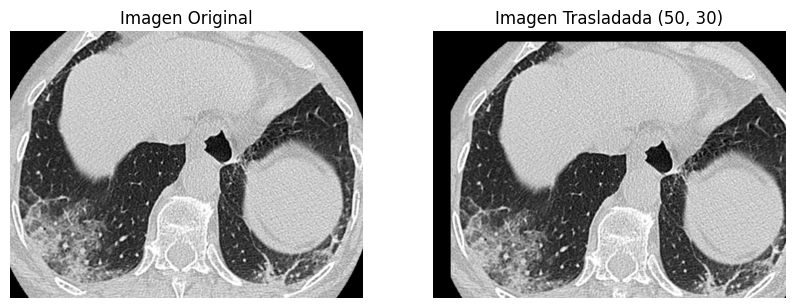

In [5]:
# Mostrar imágenes
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.imshow(imagen, cmap="gray")
plt.title("Imagen Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(imagen_trasladada, cmap="gray")
plt.title("Imagen Trasladada (50, 30)")
plt.axis("off")

plt.show()

**Resultado:** el corte de TC se desplazó completo hacia la derecha y hacia abajo, sin cambiar su tamaño, forma ni orientación. Aparece una franja negra de 50 px en el borde izquierdo y otra de 30 px en el borde superior, que son las zonas sin información. A cambio, se pierde la misma cantidad de píxeles en los bordes derecho e inferior.

## Ejercicio 2. Traslación con valores decimales

Se aplica un desplazamiento fraccional de **(20.5, 15.5)** píxeles. Como la nueva posición de cada píxel cae entre dos posiciones enteras, `cv2.warpAffine` necesita **interpolar** para calcular su valor. Con `flags=cv2.INTER_LINEAR` se usa la interpolación bilineal, que promedia los píxeles vecinos según su distancia.

Para compararla con la traslación entera, también se calcula la traslación de **(20, 15)** píxeles.

In [6]:
# Traslación con valores decimales
tx_dec, ty_dec = 20.5, 15.5
M_dec = np.float32([[1, 0, tx_dec], [0, 1, ty_dec]])
imagen_trasladada_dec = cv2.warpAffine(imagen, M_dec, (ancho, alto), flags=cv2.INTER_LINEAR)

# Traslación entera equivalente para comparar
M_ent = np.float32([[1, 0, 20], [0, 1, 15]])
imagen_trasladada_ent = cv2.warpAffine(imagen, M_ent, (ancho, alto))

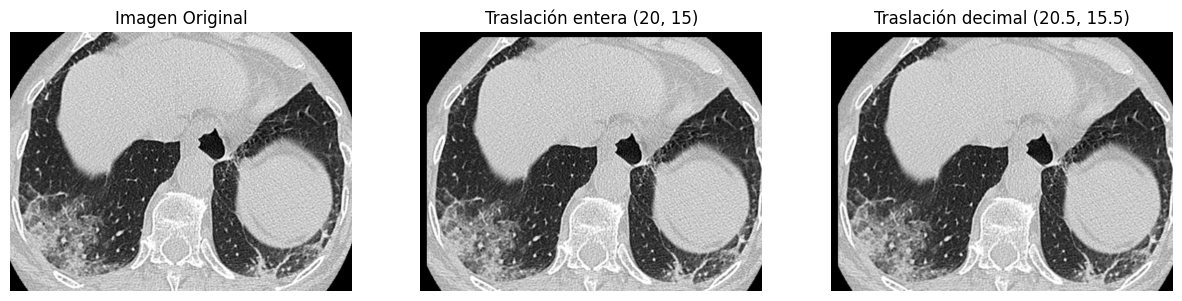

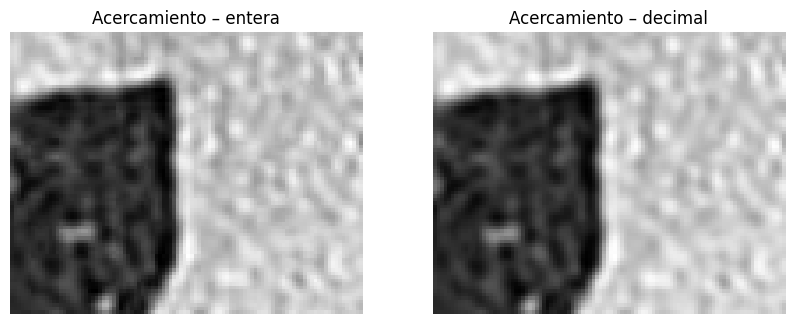

In [7]:
# Mostrar imágenes completas
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(imagen, cmap="gray")
plt.title("Imagen Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(imagen_trasladada_ent, cmap="gray")
plt.title("Traslación entera (20, 15)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(imagen_trasladada_dec, cmap="gray")
plt.title("Traslación decimal (20.5, 15.5)")
plt.axis("off")

plt.show()

# Acercamiento a una misma zona para comparar el detalle
y1, y2, x1, x2 = 320, 400, 470, 570
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.imshow(imagen_trasladada_ent[y1:y2, x1:x2], cmap="gray", interpolation="nearest")
plt.title("Acercamiento – entera")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(imagen_trasladada_dec[y1:y2, x1:x2], cmap="gray", interpolation="nearest")
plt.title("Acercamiento – decimal")
plt.axis("off")

plt.show()

**Resultado:** a simple vista, las dos traslaciones se ven prácticamente iguales, porque solo difieren por medio píxel. En el acercamiento sí se nota la diferencia:
- En la **traslación entera** cada píxel conserva exactamente su valor original y los bordes de los vasos y del hueso se mantienen nítidos.
- En la **traslación decimal** cada píxel nuevo es un promedio de sus vecinos, así que los bordes se ven ligeramente **más suaves o difuminados** y las franjas negras del borde tienen una transición gris en lugar de un corte limpio.

## Ejercicio 3. Traslación + Rotación

A partir de este ejercicio se utiliza la radiografía de tórax. Primero se traslada **(50, 30)** px y después se gira **45°** respecto al centro de la imagen.

`cv2.getRotationMatrix2D(centro, ángulo, escala)` genera la matriz de rotación:
- El centro se calcula como `(ancho // 2, alto // 2)`.
- Un ángulo positivo gira en sentido **antihorario**.
- Una escala de `1.0` mantiene el tamaño.

La rotación se aplica sobre la imagen **ya trasladada**, por lo que el resultado combina las dos transformaciones.

In [8]:
# Cargar la imagen en escala de grises
imagen_rx = cv2.imread("RX_torax.jpg", cv2.IMREAD_GRAYSCALE)

# Dimensiones de la imagen
alto, ancho = imagen_rx.shape
print("Dimensiones (alto, ancho):", imagen_rx.shape)

Dimensiones (alto, ancho): (2200, 2200)


In [9]:
# Definir traslación (50 píxeles en X, 30 píxeles en Y)
tx, ty = 50, 30
M_translacion = np.float32([[1, 0, tx], [0, 1, ty]])

# Aplicar traslación
imagen_trasladada = cv2.warpAffine(imagen_rx, M_translacion, (ancho, alto))

In [10]:
# Definir rotación (45° alrededor del centro de la imagen)
angulo = 45
centro = (ancho // 2, alto // 2)  # Centro de la imagen
escala = 1.0  # Sin cambios en el tamaño

M_rotacion = cv2.getRotationMatrix2D(centro, angulo, escala)

# Aplicar rotación sobre la imagen trasladada
imagen_final = cv2.warpAffine(imagen_trasladada, M_rotacion, (ancho, alto))

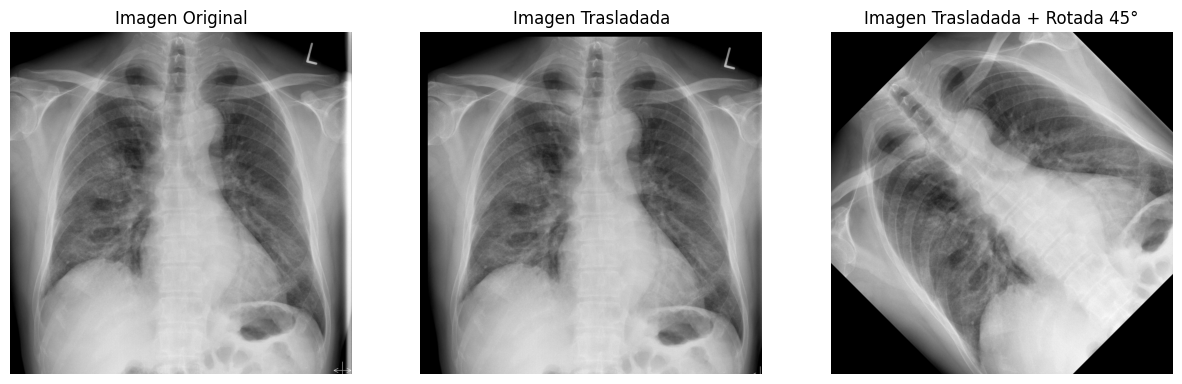

In [11]:
# Mostrar imágenes
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(imagen_rx, cmap="gray")
plt.title("Imagen Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(imagen_trasladada, cmap="gray")
plt.title("Imagen Trasladada")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(imagen_final, cmap="gray")
plt.title("Imagen Trasladada + Rotada 45°")
plt.axis("off")

plt.show()

**Resultado:**
- La traslación de 50 × 30 px apenas se nota en la radiografía, que mide 2200 × 2200 px. Se aprecia solo como una franja negra delgada en los bordes superior e izquierdo.
- Después de la rotación de 45°, el tórax queda inclinado en diagonal. Como el tamaño de salida es el mismo que el de la original, las esquinas de la radiografía se recortan y aparecen triángulos negros en las cuatro esquinas.
- La forma y el tamaño de las estructuras (costillas, corazón, campos pulmonares) no cambian, solo su posición y orientación.

## Ejercicio 4. Traslación + Rotación + Escalado

Se repite la traslación de (50, 30) px y la rotación de 45°, pero ahora `getRotationMatrix2D` incluye un **factor de escala**. Para observar la diferencia se usan dos valores:
- **0.7** (70 %): reduce la imagen.
- **1.3** (130 %): la amplía.

En ambos casos la escala se aplica respecto al centro de la imagen.

In [12]:
# Definir traslación (50 píxeles en X, 30 píxeles en Y)
tx, ty = 50, 30
M_translacion = np.float32([[1, 0, tx], [0, 1, ty]])
imagen_trasladada = cv2.warpAffine(imagen_rx, M_translacion, (ancho, alto))

# Definir rotación + escalado (45° alrededor del centro)
angulo = 45
escala_menor = 0.7   # 70 %
escala_mayor = 1.3   # 130 %
centro = (ancho // 2, alto // 2)

M_rot_esc_menor = cv2.getRotationMatrix2D(centro, angulo, escala_menor)
M_rot_esc_mayor = cv2.getRotationMatrix2D(centro, angulo, escala_mayor)

# Aplicar rotación y escalado sobre la imagen trasladada
imagen_final_menor = cv2.warpAffine(imagen_trasladada, M_rot_esc_menor, (ancho, alto))
imagen_final_mayor = cv2.warpAffine(imagen_trasladada, M_rot_esc_mayor, (ancho, alto))

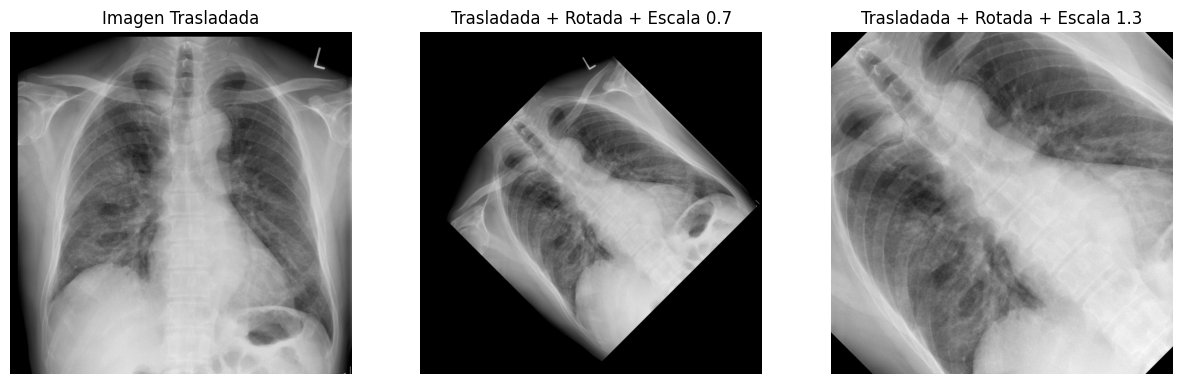

In [13]:
# Mostrar imágenes
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(imagen_trasladada, cmap="gray")
plt.title("Imagen Trasladada")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(imagen_final_menor, cmap="gray")
plt.title("Trasladada + Rotada + Escala 0.7")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(imagen_final_mayor, cmap="gray")
plt.title("Trasladada + Rotada + Escala 1.3")
plt.axis("off")

plt.show()

**Resultado:**
- **Escala 0.7:** la radiografía se ve más pequeña y girada, y queda prácticamente completa dentro del marco: casi no se recortan las esquinas, pero aumenta el área negra alrededor. Esto permite ver toda la imagen después de rotarla.
- **Escala 1.3:** la radiografía se amplía y ocupa todo el marco, de modo que los espacios negros prácticamente desaparecen. A cambio, se pierden los bordes de la imagen (hombros, ángulos costofrénicos), aunque las estructuras centrales, como el corazón y el mediastino, se ven más grandes.

Es decir, el factor de escala permite elegir entre conservar toda la imagen o acercarse a una zona de interés.

## Ejercicio 5. Transformación Afín y Radial

### a) Transformación afín con cuatro puntos de referencia
Una transformación afín puede combinar traslación, rotación, escalado e inclinación (*shear*), y conserva las líneas rectas y el paralelismo. Queda definida por una matriz de 2 × 3, es decir, 6 incógnitas, así que se necesitan al menos **3 pares de puntos**.

Como la práctica pide **cuatro puntos de referencia**, se definieron 4 puntos en la imagen original, cerca de las esquinas, y sus 4 posiciones de destino. La matriz se calculó con `cv2.estimateAffine2D`, que obtiene la transformación afín que mejor relaciona todos los pares de puntos. Los puntos se definen en proporción al tamaño de la imagen para que el efecto sea visible en la radiografía de 2200 px.

In [14]:
filas, columnas = imagen_rx.shape

# Cuatro puntos originales (cerca de las esquinas)
pts1 = np.float32([[0.15*columnas, 0.15*filas],
                   [0.85*columnas, 0.15*filas],
                   [0.15*columnas, 0.85*filas],
                   [0.85*columnas, 0.85*filas]])

# Cuatro puntos transformados (inclinación hacia la derecha y compresión vertical)
pts2 = np.float32([[0.30*columnas, 0.20*filas],
                   [0.95*columnas, 0.25*filas],
                   [0.05*columnas, 0.75*filas],
                   [0.70*columnas, 0.80*filas]])

# Obtener la matriz de transformación afín a partir de los 4 pares de puntos
M_afin, _ = cv2.estimateAffine2D(pts1, pts2)
print("Matriz afín:\n", np.round(M_afin, 3))

# Aplicar la transformación
imagen_afin = cv2.warpAffine(imagen_rx, M_afin, (columnas, filas))

Matriz afín:
 [[ 9.29000e-01 -3.57000e-01  4.71429e+02]
 [ 7.10000e-02  7.86000e-01  1.57143e+02]]


### b) Distorsión radial (ojo de pez)
La distorsión radial aparece por la curvatura de los lentes: los píxeles se desplazan más mientras más lejos están del centro. Se modela con:
- La **matriz intrínseca** $K$, que contiene la distancia focal $f$ y el centro óptico $(c_x, c_y)$.
- Los **coeficientes de distorsión** $k_1, k_2$.

$$x_d = x\,(1 + k_1 r^2 + k_2 r^4), \qquad y_d = y\,(1 + k_1 r^2 + k_2 r^4)$$

Se utilizó `cv2.undistort`, igual que en el notebook de la clase, pero con el centro óptico en el centro de la radiografía y con $k_1$ positivo. `undistort` "corrige" una supuesta distorsión de cojín, y al aplicarlo sobre una imagen sin distorsión se genera el efecto contrario: una **distorsión de barril**, parecida a la de un lente ojo de pez.

In [15]:
# Matriz de calibración de la cámara y coeficientes de distorsión
h, w = imagen_rx.shape[:2]
f = w / 2
K = np.array([[f, 0, w / 2], [0, f, h / 2], [0, 0, 1]])   # Matriz intrínseca
dist_coef = np.array([0.3, 0.05, 0, 0, 0])               # Coeficientes de distorsión radial

# Aplicar la distorsión radial
new_K, roi = cv2.getOptimalNewCameraMatrix(K, dist_coef, (w, h), 1, (w, h))
imagen_radial = cv2.undistort(imagen_rx, K, dist_coef, None, new_K)

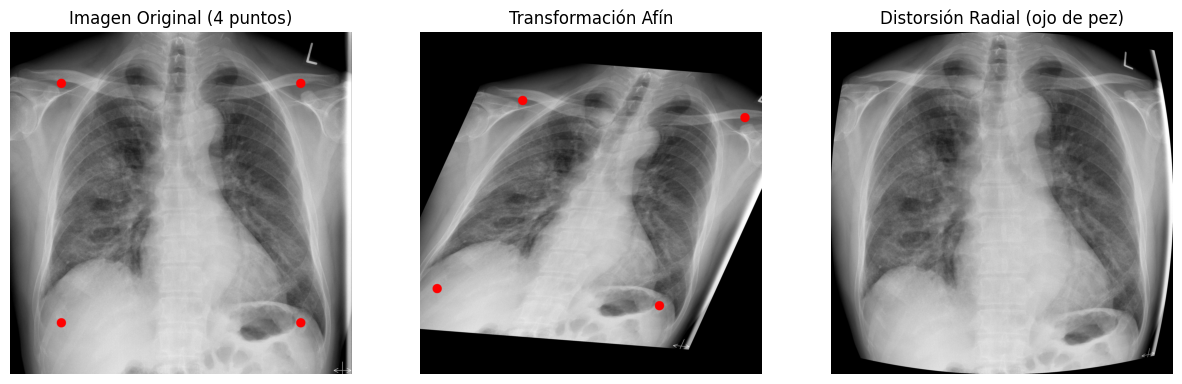

In [16]:
# Dibujar los puntos de referencia para visualizar la transformación afín
original_pts = cv2.cvtColor(imagen_rx, cv2.COLOR_GRAY2RGB)
afin_pts = cv2.cvtColor(imagen_afin, cv2.COLOR_GRAY2RGB)
for p in pts1:
    cv2.circle(original_pts, (int(p[0]), int(p[1])), 30, (255, 0, 0), -1)
for p in pts2:
    cv2.circle(afin_pts, (int(p[0]), int(p[1])), 30, (255, 0, 0), -1)

# Mostrar imágenes
plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(original_pts)
plt.title("Imagen Original (4 puntos)")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(afin_pts)
plt.title("Transformación Afín")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(imagen_radial, cmap="gray")
plt.title("Distorsión Radial (ojo de pez)")
plt.axis("off")

plt.show()